# Assignment V

**Professor: Edgar Alejandro Guerrero Arroyo  
Student: Alejandro Caamaño Granados (326056144)  
Course: MEMAD 26B  
Due date: 3/nov/26**

**Abstract**  
The goal is to revise some relevant aspects of stochastic optimization
models, especially the minibatch gradient descent and Adam methods.
Please upload your solutions to Classroom before November 3rd.

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
import time

from scipy.optimize import minimize

## Problem 1

Consider the following function  
$$ f(x) = 2^{cos(x^2)} \text{ , } \quad x \in (-\pi , \pi)$$  
Next, do the following:

*   Compute 500 pair sample data $D = \{x_i, f(x_i)\}$ where the $x_i$ are equispaced.
*   Make a plot of D.
*   Consider a polynomial model of degree $\mathscr{N}$:
$$ h(x_i;\theta) = \hat{y}_i = \sum_{\ell=\theta}^{\mathcal{N}} \theta_\ell x^\ell_i, \quad \theta = (\theta_0, \theta_1, \theta_2, \dots, \theta_\mathcal{N}) \in \mathbb{R}^{\mathcal{N}+1}$$
*   Consider a MSE loss and cost functions:
$$ Loss(y_i, \hat{y}_i) = (y_i - \hat{y}_i)^2, $$
$$ Cost(\theta; D) = \frac{1}{m} \sum_{i=1}^{m} Loss(y_i, \hat{y}_i) $$
*   Code a Python script to solve the associated optimization problem using
some deterministic line search algorithm. You can try out $\mathcal{N} = 8$ for
instance.
*   Make a plot of the solution against $f(x_i)$ and show in another plot how
the cost decreases as the iterations go by.


In [55]:
def f_true(x):
    """Target function f(x) = 2^(cos(x^2))"""
    return 2.0 ** np.cos(x**2)

In [68]:
def compute_cost_and_grad(theta, X, y):
    """
    Computes the MSE cost and gradient for polynomial regression.
    X: Vandermonde matrix of shape (m, N+1)
    y: target values of shape (m,)
    theta: parameters of shape (N+1,)
    """
    m = len(y)
    predictions = X @ theta
    error = predictions - y
    cost = np.mean(error ** 2)
    grad = (2.0 / m) * (X.T @ error)
    return cost, grad

def wolfe_line_search(theta, p, grad, X, y, c1=1e-4, c2=0.9, alpha_init=1.0):
    """
    Performs a backtracking line search satisfying the Wolfe conditions:
    1. Armijo condition (sufficient decrease)
    2. Curvature condition
    """
    alpha = alpha_init
    phi_0, dphi_0 = compute_cost_and_grad(theta, X, y)[0], np.dot(grad, p)
    phi_prev = phi_0

    max_iter = 30
    for i in range(max_iter):
        theta_new = theta + alpha * p
        phi_new, grad_new = compute_cost_and_grad(theta_new, X, y)

        # Armijo condition check
        if phi_new > phi_0 + c1 * alpha * dphi_0 or (i > 0 and phi_new >= phi_prev):
            alpha = 0.5 * alpha  # Backtrack step size
            continue

        # Curvature condition check
        dphi_new = np.dot(grad_new, p)
        if dphi_new < c2 * dphi_0:
            alpha *= 1.5  # Expand step size if slope is still too steep
            continue

        break
    return max(alpha, 1e-8)

def optimize_polynomial_with_standardization(N, m=200, max_iter=2500, tol=1e-6):
    """
    Optimizes polynomial coefficients using Gradient Descent + Wolfe Line Search
    with Feature Standardization to prevent numerical overflow for large N.
    """
    # Generate data
    x = np.linspace(-np.pi + 1e-5, np.pi - 1e-5, m)
    y = f_true(x)

    # Construct Vandermonde matrix for raw polynomial features [1, x, x^2, ..., x^N]
    X = np.vander(x, N + 1, increasing=True)

    # Feature Standardization (exclude intercept column index 0)
    X_mean = np.mean(X[:, 1:], axis=0)
    X_std = np.std(X[:, 1:], axis=0)

    X_scaled = X.copy()
    X_scaled[:, 1:] = (X[:, 1:] - X_mean) / X_std

    # Initialize parameters in the scaled space
    theta_scaled = np.zeros(N + 1)
    cost_history = []

    for iteration in range(max_iter):
        cost, grad = compute_cost_and_grad(theta_scaled, X_scaled, y)
        cost_history.append(cost)

        # Check convergence based on gradient norm
        if np.linalg.norm(grad) < tol:
            print(f"Converged at iteration {iteration} for N={N}")
            break

        # Descent direction is the negative gradient
        p = -grad

        # Line search to find optimal step size alpha satisfying Wolfe conditions
        alpha = wolfe_line_search(theta_scaled, p, grad, X_scaled, y)

        # Update scaled parameters
        theta_scaled += alpha * p

    # Transform parameters back to the original (unscaled) monomial basis: y = X @ theta
    theta = np.zeros(N + 1)
    theta[0] = theta_scaled[0] - np.sum(theta_scaled[1:] * X_mean / X_std)
    theta[1:] = theta_scaled[1:] / X_std

    return theta, cost_history, x, y

def evaluate_and_report_results(algorithm_name, theta, cost_history, x_data, y_clean, y_noisy, N, start_time=None):
    """
    Computes and prints a standardized performance report for any polynomial regression optimizer.
    """
    X_eval = np.vander(x_data, N + 1, increasing=True)
    y_pred = X_eval @ theta

    final_train_cost = cost_history[-1]
    noise_free_mse = np.mean((y_pred - y_clean) ** 2)
    max_absolute_error = np.max(np.abs(y_pred - y_clean))

    print("\n" + "=" * 60)
    print(f"PERFORMANCE REPORT: {algorithm_name} (Degree N = {N})")
    print("=" * 60)
    print(f" • Total Iterations / Epochs  : {len(cost_history)}")
    print(f" • Final Training Cost (MSE)  : {final_train_cost:.6f}")
    print(f" • True Signal MSE (vs Clean) : {noise_free_mse:.6f}")
    print(f" • Max Absolute Deviation     : {max_absolute_error:.6f}")

    if start_time is not None:
        elapsed = time.time() - start_time
        print(f" • Execution Time             : {elapsed:.4f} seconds")

    print("\n Optimized Parameters (θ):")
    for i, val in enumerate(theta):
        print(f"   θ_{i:2d} = {val:12.6f}")
    print("=" * 60 + "\n")

Compute 500 pair sample data and make plot of D

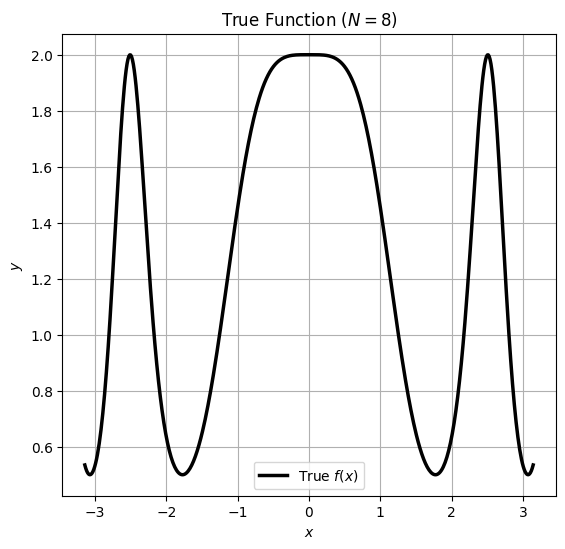

In [33]:
# Test multiple values of N, including high degree N=12
N_values = [8]

plt.figure(figsize=(14, 6))

# Plot 1: Polynomial fits vs True Function
plt.subplot(1, 2, 1)
x_dense = np.linspace(-np.pi, np.pi, 500)
plt.plot(x_dense, f_true(x_dense), 'k-', linewidth=2.5, label='True $f(x)$')

plt.title('True Function ($N=8$)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)

Solve polynomial regression optimization problem using Gradient Descent with a Wolfe Conditions Line Search.


PERFORMANCE REPORT: Wolfe Line Search GD (Degree N = 8)
 • Total Iterations / Epochs  : 2500
 • Final Training Cost (MSE)  : 0.068549
 • True Signal MSE (vs Clean) : 0.066067
 • Max Absolute Deviation     : 0.861911
 • Execution Time             : 0.1760 seconds

 Optimized Parameters (θ):
   θ_ 0 =     2.131077
   θ_ 1 =    -0.000000
   θ_ 2 =    -0.977738
   θ_ 3 =     0.000000
   θ_ 4 =     0.170152
   θ_ 5 =    -0.000000
   θ_ 6 =     0.003134
   θ_ 7 =     0.000000
   θ_ 8 =    -0.001306



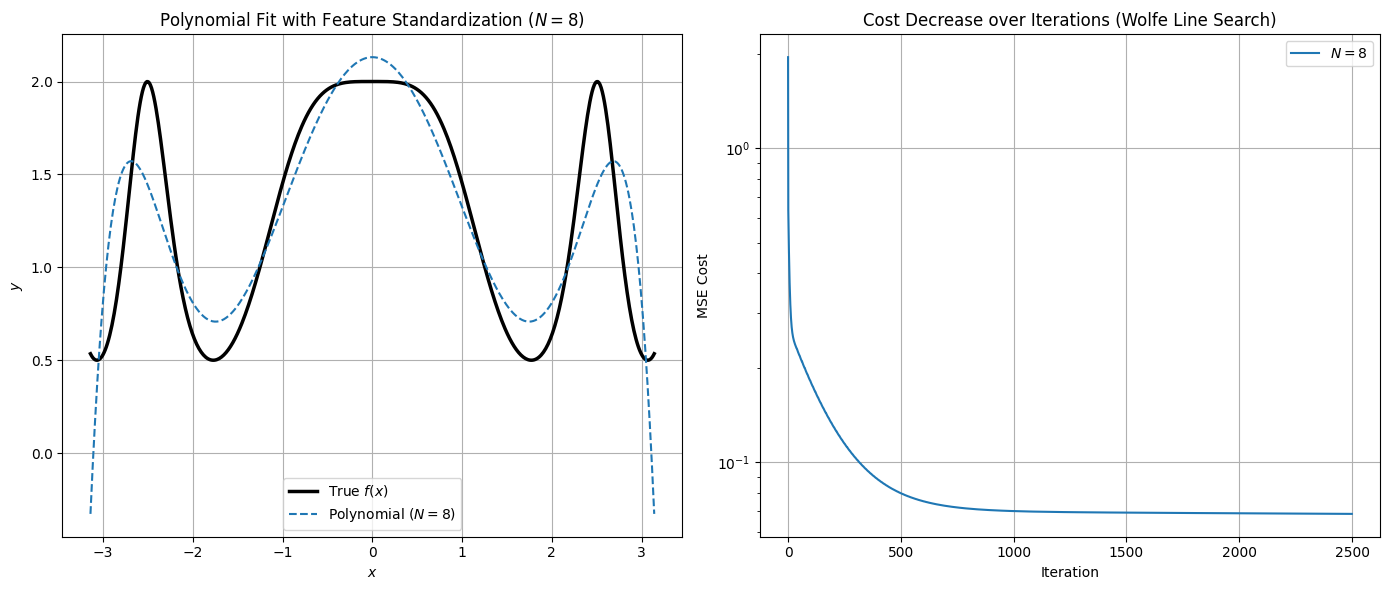

In [69]:
N_values = [8]
x_dense = np.linspace(-np.pi, np.pi, 500)
y_clean_dense = f_true(x_dense)

plt.figure(figsize=(14, 6))

# Plot 1: Polynomial fits vs True Function
plt.subplot(1, 2, 1)
plt.plot(x_dense, y_clean_dense, 'k-', linewidth=2.5, label='True $f(x)$')

for N in N_values:
    start_time = time.time()
    theta, cost_history, x_data, y_noisy = optimize_polynomial_with_standardization(N=N)

    # Evaluate and print detailed performance metrics report
    evaluate_and_report_results(
        algorithm_name="Wolfe Line Search GD",
        theta=theta,
        cost_history=cost_history,
        x_data=x_dense,
        y_clean=y_clean_dense,
        y_noisy=y_noisy,
        N=N,
        start_time=start_time
    )

    X_dense = np.vander(x_dense, N + 1, increasing=True)
    y_pred = X_dense @ theta
    plt.plot(x_dense, y_pred, '--', label=f'Polynomial ($N={N}$)')

plt.title('Polynomial Fit with Feature Standardization ($N=8$)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)

# Plot 2: Cost History for different N values
plt.subplot(1, 2, 2)
for N in N_values:
    _, cost_history, _, _ = optimize_polynomial_with_standardization(N=N)
    plt.plot(cost_history, label=f'$N={N}$')
    # print(f"Lowest cost reached for N={N}: {min(cost_history)}")

plt.title('Cost Decrease over Iterations (Wolfe Line Search)')
plt.xlabel('Iteration')
plt.ylabel('MSE Cost')
plt.yscale('log')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

We can see that the Wolfe Line Search, being completely deterministic, produces a smooth Cost curve. The model quickly reached a low Cost value, and eventually plateaued at around the 1000th iteration.

## Problem 2

Attempt to find a better size for the parametric model in the previous problem
by solving again for several values of $\mathcal{N}$. Make some plots showing your findings.
From herein you can fix this value of $\mathcal{N}$ for the remaining problems.

Converged at iteration 1 for N=3

PERFORMANCE REPORT: Wolfe Line Search GD (Degree N = 3)
 • Total Iterations / Epochs  : 2
 • Final Training Cost (MSE)  : 0.264180
 • True Signal MSE (vs Clean) : 0.264893
 • Max Absolute Deviation     : 0.982080
 • Execution Time             : 0.0014 seconds

 Optimized Parameters (θ):
   θ_ 0 =     1.559375
   θ_ 1 =    -0.000000
   θ_ 2 =    -0.085840
   θ_ 3 =    -0.000000

Converged at iteration 315 for N=4

PERFORMANCE REPORT: Wolfe Line Search GD (Degree N = 4)
 • Total Iterations / Epochs  : 316
 • Final Training Cost (MSE)  : 0.235468
 • True Signal MSE (vs Clean) : 0.234861
 • Max Absolute Deviation     : 1.106683
 • Execution Time             : 0.0223 seconds

 Optimized Parameters (θ):
   θ_ 0 =     1.750026
   θ_ 1 =     0.000000
   θ_ 2 =    -0.277111
   θ_ 3 =    -0.000000
   θ_ 4 =     0.022387


PERFORMANCE REPORT: Wolfe Line Search GD (Degree N = 8)
 • Total Iterations / Epochs  : 2500
 • Final Training Cost (MSE)  : 0.068549
 • True 

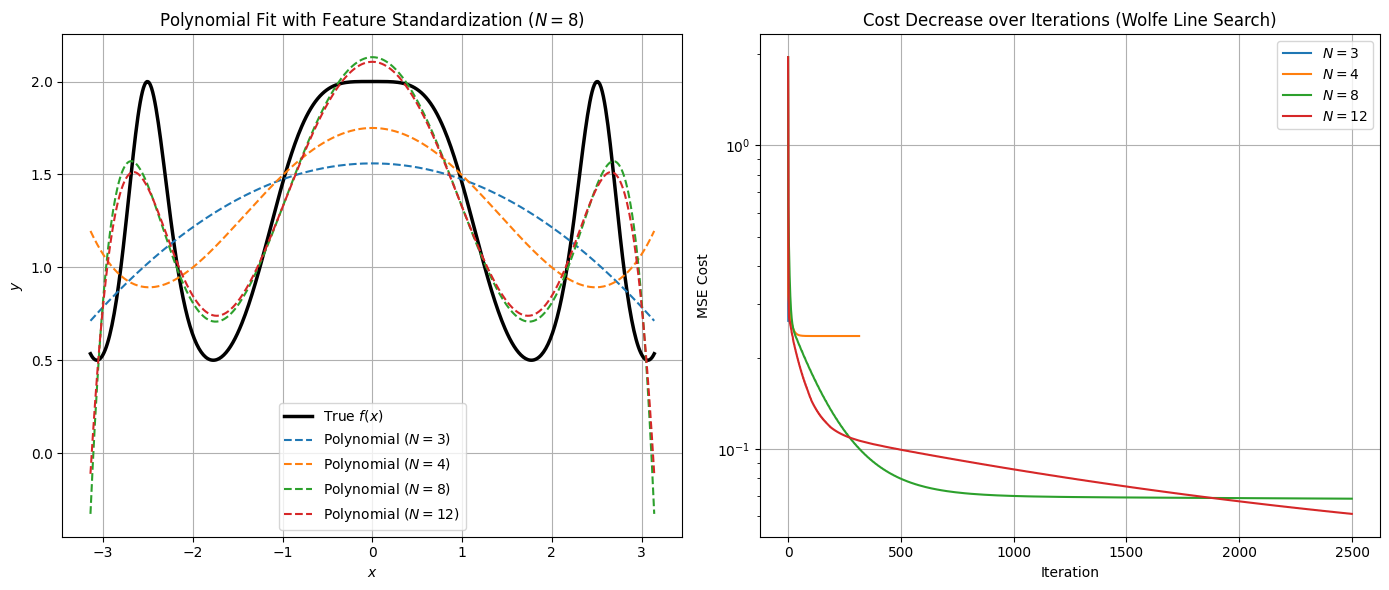

In [70]:
N_values = [3,4,8,12]
x_dense = np.linspace(-np.pi, np.pi, 500)
y_clean_dense = f_true(x_dense)

plt.figure(figsize=(14, 6))

# Plot 1: Polynomial fits vs True Function
plt.subplot(1, 2, 1)
plt.plot(x_dense, y_clean_dense, 'k-', linewidth=2.5, label='True $f(x)$')

for N in N_values:
    start_time = time.time()
    theta, cost_history, x_data, y_noisy = optimize_polynomial_with_standardization(N=N)

    # Evaluate and print detailed performance metrics report
    evaluate_and_report_results(
        algorithm_name="Wolfe Line Search GD",
        theta=theta,
        cost_history=cost_history,
        x_data=x_dense,
        y_clean=y_clean_dense,
        y_noisy=y_noisy,
        N=N,
        start_time=start_time
    )

    X_dense = np.vander(x_dense, N + 1, increasing=True)
    y_pred = X_dense @ theta
    plt.plot(x_dense, y_pred, '--', label=f'Polynomial ($N={N}$)')

plt.title('Polynomial Fit with Feature Standardization ($N=8$)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)

# Plot 2: Cost History for different N values
plt.subplot(1, 2, 2)
for N in N_values:
    _, cost_history, _, _ = optimize_polynomial_with_standardization(N=N)
    plt.plot(cost_history, label=f'$N={N}$')
    # print(f"Lowest cost reached for N={N}: {min(cost_history)}")

plt.title('Cost Decrease over Iterations (Wolfe Line Search)')
plt.xlabel('Iteration')
plt.ylabel('MSE Cost')
plt.yscale('log')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Running the same script as before for many values of $N$, we can see that polynomials with lower values of $N$ reach a minimum Cost value and are stopped by the search function. However, models with more coefficients tend to last all 2500 iterations. The model with $N=12$ was still dropping its Cost when it reached the last iteration. This behaviour makes me think that models with even more parameters could achieve a better result (lower Cost) in fewer iterations.

At first, the execution of the model with $N=12$ created many runtime warnings. Its predictions $\hat{y}_i = X\theta$ grew excessively large and exceeded the maximum limit of standard 64-bit floating-point numbers. To fix this, we standardized our feature column.

## Problem 3

Make a script to solve Problem 1 using a minibach gradient descent with a
constant learning rate $α$. Make a plot of the solution against $f(x_i)$ and show in
another plot how the cost decreases as the iterations go by.

In [71]:
def compute_cost_and_grad_mb(theta, X, y):
    """
    Computes the MSE cost and gradient over a batch/mini-batch.
    X: Vandermonde sub-matrix of shape (batch_size, N+1)
    y: target sub-vector of shape (batch_size,)
    theta: parameters of shape (N+1,)
    """
    batch_size = len(y)
    predictions = X @ theta
    error = predictions - y
    cost = np.mean(error ** 2)
    grad = (2.0 / batch_size) * (X.T @ error)
    return cost, grad

def minibatch_gradient_descent(N, m=200, batch_size=32, lr=0.01, epochs=2000, seed=42):
    """
    Optimizes polynomial coefficients using Mini-batch Gradient Descent with a constant learning rate.
    """
    np.random.seed(seed)

    # Generate data
    x = np.linspace(-np.pi + 1e-5, np.pi - 1e-5, m)
    y = f_true(x)

    # Construct Vandermonde matrix for polynomial features [1, x, x^2, ..., x^N]
    X = np.vander(x, N + 1, increasing=True)

    # Feature Scaling (Normalization) to stabilize constant learning rate updates across polynomial terms
    X_mean = np.mean(X[:, 1:], axis=0)
    X_std = np.std(X[:, 1:], axis=0)
    X_scaled = X.copy()
    X_scaled[:, 1:] = (X[:, 1:] - X_mean) / X_std

    # Initialize parameters
    theta_scaled = np.zeros(N + 1)

    cost_history = []

    num_batches = int(np.ceil(m / batch_size))

    for epoch in range(epochs):
        # Shuffle dataset at the beginning of each epoch
        indices = np.random.permutation(m)
        X_shuffled = X_scaled[indices]
        y_shuffled = y[indices]

        epoch_cost = 0.0

        for b in range(num_batches):
            start_idx = b * batch_size
            end_idx = min(start_idx + batch_size, m)

            X_batch = X_shuffled[start_idx:end_idx]
            y_batch = y_shuffled[start_idx:end_idx]

            # Compute batch cost and gradient
            batch_cost, grad = compute_cost_and_grad_mb(theta_scaled, X_batch, y_batch)
            epoch_cost += batch_cost * (end_idx - start_idx)

            # Parameter update step with constant learning rate alpha
            theta_scaled -= lr * grad

        # Log average epoch cost over all full dataset points
        epoch_cost /= m
        cost_history.append(epoch_cost)

    # Unscale parameters back to original polynomial basis: y = X @ theta
    theta = np.zeros(N + 1)
    theta[0] = theta_scaled[0] - np.sum(theta_scaled[1:] * X_mean / X_std)
    theta[1:] = theta_scaled[1:] / X_std

    return theta, cost_history, x, y


PERFORMANCE REPORT: Mini-batch Gradient Descent (Degree N = 8)
 • Total Iterations / Epochs  : 2500
 • Final Training Cost (MSE)  : 0.074956
 • True Signal MSE (vs Clean) : 0.072479
 • Max Absolute Deviation     : 0.692867
 • Execution Time             : 0.2422 seconds

 Optimized Parameters (θ):
   θ_ 0 =     2.037263
   θ_ 1 =    -0.002192
   θ_ 2 =    -0.827481
   θ_ 3 =     0.000098
   θ_ 4 =     0.133315
   θ_ 5 =    -0.000006
   θ_ 6 =     0.004715
   θ_ 7 =    -0.000003
   θ_ 8 =    -0.001215



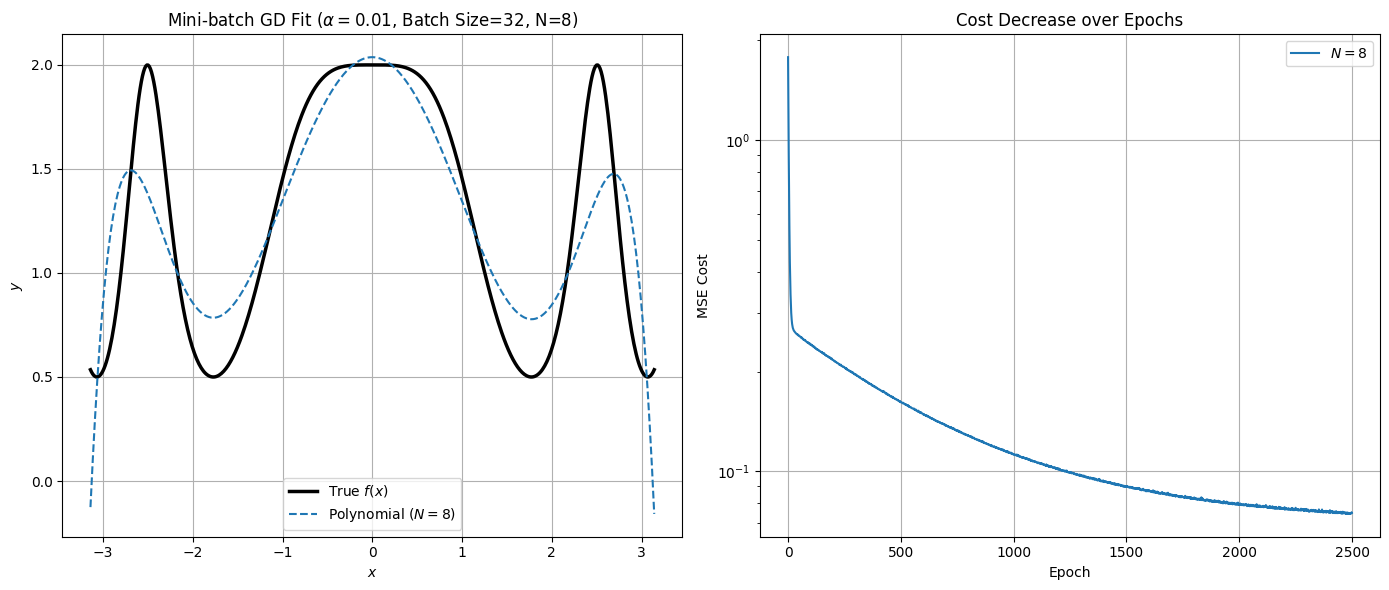

In [64]:
N_values = [8]
batch_size = 32
learning_rate = 0.01
epochs = 2500

x_dense = np.linspace(-np.pi, np.pi, 500)
y_clean_dense = f_true(x_dense)

plt.figure(figsize=(14, 6))

# Plot 1: Polynomial fits vs True Function
plt.subplot(1, 2, 1)
plt.plot(x_dense, y_clean_dense, 'k-', linewidth=2.5, label='True $f(x)$')

for N in N_values:
    start_time = time.time()
    theta, cost_history, x_data, y_data = minibatch_gradient_descent(
        N=N, batch_size=batch_size, lr=learning_rate, epochs=epochs
    )

    # Evaluate and print metrics
    evaluate_and_report_results(
        algorithm_name="Mini-batch Gradient Descent",
        theta=theta,
        cost_history=cost_history,
        x_data=x_dense,
        y_clean=y_clean_dense,
        y_noisy=y_data,
        N=N,
        start_time=start_time
    )

    X_dense = np.vander(x_dense, N + 1, increasing=True)
    y_pred = X_dense @ theta
    plt.plot(x_dense, y_pred, '--', label=f'Polynomial ($N={N}$)')

plt.title(f'Mini-batch GD Fit ($\\alpha={learning_rate}$, Batch Size={batch_size}, N=8)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)

# Plot 2: Cost History over Epochs for different N values
plt.subplot(1, 2, 2)
for N in N_values:
    _, cost_history, _, _ = minibatch_gradient_descent(
        N=N, batch_size=batch_size, lr=learning_rate, epochs=epochs
    )
    plt.plot(cost_history, label=f'$N={N}$')
    # print(f"Lowest cost reached for N={N}: {min(cost_history)}")

plt.title('Cost Decrease over Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE Cost')
plt.yscale('log')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In this Cost Decrease graph, we can start to see the very small variance of the curve caused by the randomness of the mini-batches.

## Problem 4

Repeat problem 3 using Adam.

In [39]:
def compute_cost_and_grad_mb(theta, X, y):
    """
    Computes the MSE cost and gradient over a batch/mini-batch.
    X: Vandermonde sub-matrix of shape (batch_size, N+1)
    y: target sub-vector of shape (batch_size,)
    theta: parameters of shape (N+1,)
    """
    batch_size = len(y)
    predictions = X @ theta
    error = predictions - y
    cost = np.mean(error ** 2)
    grad = (2.0 / batch_size) * (X.T @ error)
    return cost, grad

def minibatch_adam(N, m=200, batch_size=32, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8, epochs=2500, seed=42):
    """
    Optimizes polynomial coefficients using Mini-batch Gradient Descent with the Adam Optimizer.
    """
    np.random.seed(seed)

    # Generate data
    x = np.linspace(-np.pi + 1e-5, np.pi - 1e-5, m)
    y = f_true(x)

    # Construct Vandermonde matrix for polynomial features [1, x, x^2, ..., x^N]
    X = np.vander(x, N + 1, increasing=True)

    # Feature Standardization for numerical stability across high-degree powers
    X_mean = np.mean(X[:, 1:], axis=0)
    X_std = np.std(X[:, 1:], axis=0)
    X_scaled = X.copy()
    X_scaled[:, 1:] = (X[:, 1:] - X_mean) / X_std

    # Initialize parameters and Adam state variables
    theta_scaled = np.zeros(N + 1)
    m_t = np.zeros(N + 1)  # 1st moment vector
    v_t = np.zeros(N + 1)  # 2nd moment vector
    t = 0                  # Timestep counter

    cost_history = []
    num_batches = int(np.ceil(m / batch_size))

    for epoch in range(epochs):
        # Shuffle dataset at start of each epoch
        indices = np.random.permutation(m)
        X_shuffled = X_scaled[indices]
        y_shuffled = y[indices]

        epoch_cost = 0.0

        for b in range(num_batches):
            start_idx = b * batch_size
            end_idx = min(start_idx + batch_size, m)

            X_batch = X_shuffled[start_idx:end_idx]
            y_batch = y_shuffled[start_idx:end_idx]

            # Compute batch cost and gradient
            batch_cost, grad = compute_cost_and_grad_mb(theta_scaled, X_batch, y_batch)
            epoch_cost += batch_cost * (end_idx - start_idx)

            # Adam Optimizer Update Step
            t += 1
            m_t = beta1 * m_t + (1.0 - beta1) * grad
            v_t = beta2 * v_t + (1.0 - beta2) * (grad ** 2)

            # Compute bias-corrected moment estimates
            m_hat = m_t / (1.0 - beta1 ** t)
            v_hat = v_t / (1.0 - beta2 ** t)

            # Parameter update with constant learning rate alpha (lr)
            theta_scaled -= lr * m_hat / (np.sqrt(v_hat) + eps)

        # Log average epoch cost across all dataset points
        epoch_cost /= m
        cost_history.append(epoch_cost)

    # Unscale parameters back to original raw monomial basis: y = X @ theta
    theta = np.zeros(N + 1)
    theta[0] = theta_scaled[0] - np.sum(theta_scaled[1:] * X_mean / X_std)
    theta[1:] = theta_scaled[1:] / X_std

    return theta, cost_history, x, y


PERFORMANCE REPORT: Mini-batch Adam (Degree N = 8)
 • Total Iterations / Epochs  : 2500
 • Final Training Cost (MSE)  : 0.072312
 • True Signal MSE (vs Clean) : 0.067267
 • Max Absolute Deviation     : 0.920816
 • Execution Time             : 0.4345 seconds

 Optimized Parameters (θ):
   θ_ 0 =     2.147087
   θ_ 1 =    -0.011455
   θ_ 2 =    -0.990443
   θ_ 3 =    -0.000197
   θ_ 4 =     0.173427
   θ_ 5 =    -0.000115
   θ_ 6 =     0.002582
   θ_ 7 =    -0.000003
   θ_ 8 =    -0.001270

Lowest cost reached for N=8: 0.0670192178952912


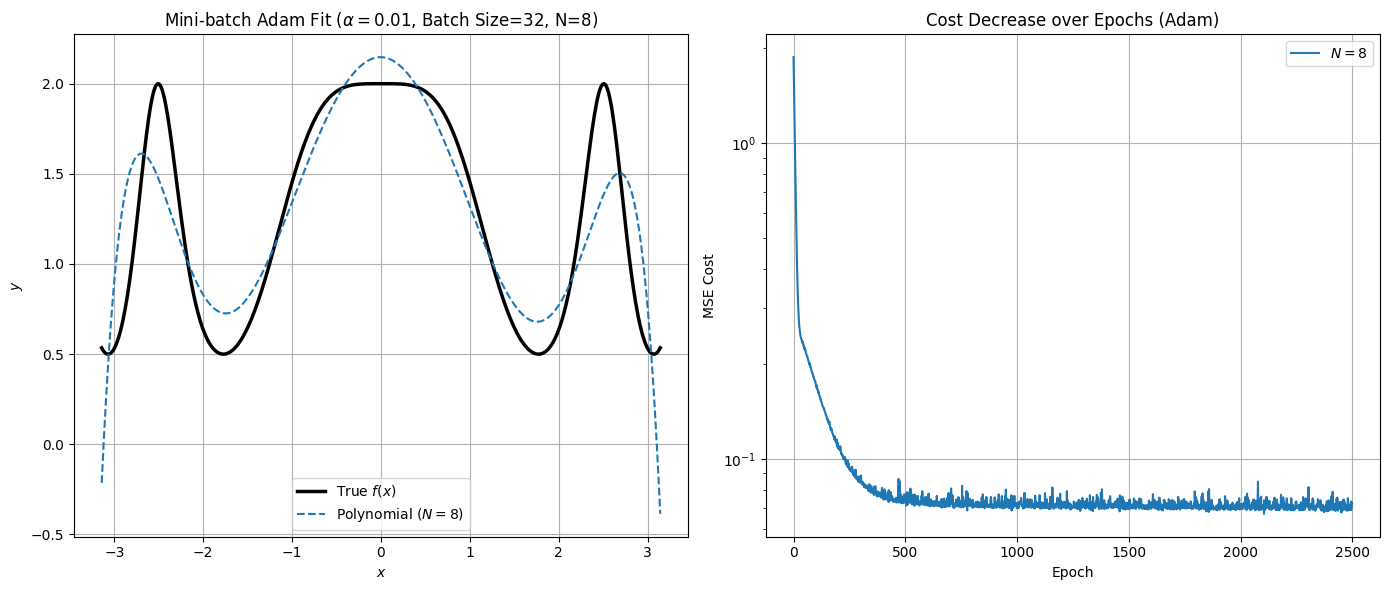

In [65]:
# Parameters
N_values = [8]
batch_size = 32
learning_rate = 0.01
epochs = 2500

x_dense = np.linspace(-np.pi, np.pi, 500)
y_clean_dense = f_true(x_dense)

plt.figure(figsize=(14, 6))

# Plot 1: Polynomial fits vs True Function
plt.subplot(1, 2, 1)
plt.plot(x_dense, y_clean_dense, 'k-', linewidth=2.5, label='True $f(x)$')

for N in N_values:
    start_time = time.time()
    theta, cost_history, x_data, y_data = minibatch_adam(
        N=N, batch_size=batch_size, lr=learning_rate, epochs=epochs
    )

    # Evaluate and report performance metrics
    evaluate_and_report_results(
        algorithm_name="Mini-batch Adam",
        theta=theta,
        cost_history=cost_history,
        x_data=x_dense,
        y_clean=y_clean_dense,
        y_noisy=y_data,
        N=N,
        start_time=start_time
    )

    X_dense = np.vander(x_dense, N + 1, increasing=True)
    y_pred = X_dense @ theta
    plt.plot(x_dense, y_pred, '--', label=f'Polynomial ($N={N}$)')

plt.title(f'Mini-batch Adam Fit ($\\alpha={learning_rate}$, Batch Size={batch_size}, N=8)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.grid(True)

# Plot 2: Cost History over Epochs for different N values
plt.subplot(1, 2, 2)
for N in N_values:
    _, cost_history, _, _ = minibatch_adam(
        N=N, batch_size=batch_size, lr=learning_rate, epochs=epochs
    )
    plt.plot(cost_history, label=f'$N={N}$')
    print(f"Lowest cost reached for N={N}: {min(cost_history)}")

plt.title('Cost Decrease over Epochs (Adam)')
plt.xlabel('Epoch')
plt.ylabel('MSE Cost')
plt.yscale('log')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Finally, we can see a much bigger variance in the Cost Decrease curve, again caused by the randomness of the mini-batches. I think the variance here is enlarged because Adam boosts the learning rate of parameters individually. If a parameter has a small gradient (such as the even values of $\theta$), Adam could be boosting its learning rate too much, causing the excess variance of the Cost curve.

## Problem 5

Make a comparison of the solutions and performance by the three algorithms
you have used to solve problem 1. Write down your conclusions and make some
plots.

The following are the results computed in the previous problems, all using $N=8$. We've run all the algorithms to the same number of epochs to fairly compare their results.

| Metric | Wolfe Line Search GD | Mini-batch Gradient Descent | Mini-batch Adam |
| :--- | :--- | :--- | :--- |
| **Total Iterations / Epochs** | 2500 | 2500 | 2500 |
| **Final Training Cost (MSE)** | 0.068549 | 0.074956 | 0.072312 |
| **True Signal MSE (vs Clean)** | 0.066067 | 0.072479 | 0.067267 |
| **Max Absolute Deviation** | 0.861911 | 0.692867 | 0.920816 |
| **Execution Time** | 0.1760 seconds | 0.2422 seconds | 0.4345 seconds |  

We can see that Wolfe Line Search algorithm achieved the best result (Final Training Cost), followed by the Adam optimizer, and lastly the Mini-batch GD. Even when evaluating the gradient across the entire dataset, Wolfe Line Search beat both Mini-batch algorithms by almost half in execution time.

Looking at the Cost Decrease graphs, we can see that the Adam optimizer reached a plateau cost the quickest.

| Metric | Wolfe Line Search GD | Mini-batch Gradient Descent | Mini-batch Adam |
| :--- | :--- | :--- | :--- |
| θ_ 0 | 2.131077 | 2.037263 | 2.147087
| θ_ 1 | -0.000000 | -0.002192 | -0.011455
| θ_ 2 | -0.977738 | -0.827481 | -0.990443
| θ_ 3 | 0.000000 | 0.000098 | -0.000197
| θ_ 4 | 0.170152 | 0.133315 | 0.173427
| θ_ 5 | -0.000000 | -0.000006 | -0.000115
| θ_ 6 | 0.003134 | 0.004715 | 0.002582
| θ_ 7 | 0.000000 | -0.000003 | -0.000003
| θ_ 8 | -0.001306 | -0.001215 | -0.001270

Very interestingly, the Mini-batch algorithms computed small but tangible coefficients for the odd values of $\theta$. Since our original $f(x)$ is an even function, these coefficients should ideally be equal to zero. I suspect these unnecessary coefficients could be caused by the randomness of the mini-batch smapling.

## Problem 6

So far, you have solved a noise-free problem, i.e.

$$ f(x) = 2^{cos(x^2)} + 𝓧 \text{, } \quad x \in (-\pi , \pi) \text{, } 𝓧 ∼ N(0, σ^2) \text{,}$$  
where you have only considered the case with $σ^2 = 0 $. Repeat problems 1-5
for the noise levels $σ^2 = 0.05, 0.1, 0.5$. Don’t forget to write down all your
conclusions and thoughts.

### Wolfe line search

In [48]:
def compute_cost_and_grad(theta, X, y):
    """
    Computes the MSE cost and gradient for polynomial regression.
    """
    m = len(y)
    predictions = X @ theta
    error = predictions - y
    cost = np.mean(error ** 2)
    grad = (2.0 / m) * (X.T @ error)
    return cost, grad

def wolfe_line_search(theta, p, grad, X, y, c1=1e-4, c2=0.9, alpha_init=1.0):
    """Performs backtracking line search satisfying the Wolfe conditions."""
    alpha = alpha_init
    phi_0, dphi_0 = compute_cost_and_grad(theta, X, y)[0], np.dot(grad, p)
    phi_prev = phi_0

    max_iter = 30
    for i in range(max_iter):
        theta_new = theta + alpha * p
        phi_new, grad_new = compute_cost_and_grad(theta_new, X, y)

        # Armijo condition check
        if phi_new > phi_0 + c1 * alpha * dphi_0 or (i > 0 and phi_new >= phi_prev):
            alpha = 0.5 * alpha
            continue

        # Curvature condition check
        dphi_new = np.dot(grad_new, p)
        if dphi_new < c2 * dphi_0:
            alpha *= 1.5
            continue

        break
    return max(alpha, 1e-8)

def optimize_with_noise(N, sigma_sq, m=200, max_iter=500, tol=1e-6, seed=42):
    """
    Generates noisy data and optimizes polynomial coefficients using
    Gradient Descent + Wolfe Line Search with Feature Standardization.
    """
    np.random.seed(seed)

    # 1. Generate clean data domain
    x = np.linspace(-np.pi + 1e-5, np.pi - 1e-5, m)
    y_clean = f_true(x)

    # 2. Add Gaussian noise N(0, sigma^2)
    noise = np.random.normal(loc=0.0, scale=np.sqrt(sigma_sq), size=m)
    y_noisy = y_clean + noise

    # 3. Construct Vandermonde matrix
    X = np.vander(x, N + 1, increasing=True)

    # 4. Feature Standardization for stability
    X_mean = np.mean(X[:, 1:], axis=0)
    X_std = np.std(X[:, 1:], axis=0)

    X_scaled = X.copy()
    X_scaled[:, 1:] = (X[:, 1:] - X_mean) / X_std

    # 5. Optimization loop
    theta_scaled = np.zeros(N + 1)
    cost_history = []

    for iteration in range(max_iter):
        cost, grad = compute_cost_and_grad(theta_scaled, X_scaled, y_noisy)
        cost_history.append(cost)

        if np.linalg.norm(grad) < tol:
            break

        p = -grad
        alpha = wolfe_line_search(theta_scaled, p, grad, X_scaled, y_noisy)
        theta_scaled += alpha * p

    # 6. Unscale parameters back to raw monomial basis
    theta = np.zeros(N + 1)
    theta[0] = theta_scaled[0] - np.sum(theta_scaled[1:] * X_mean / X_std)
    theta[1:] = theta_scaled[1:] / X_std

    return theta, cost_history, x, y_noisy

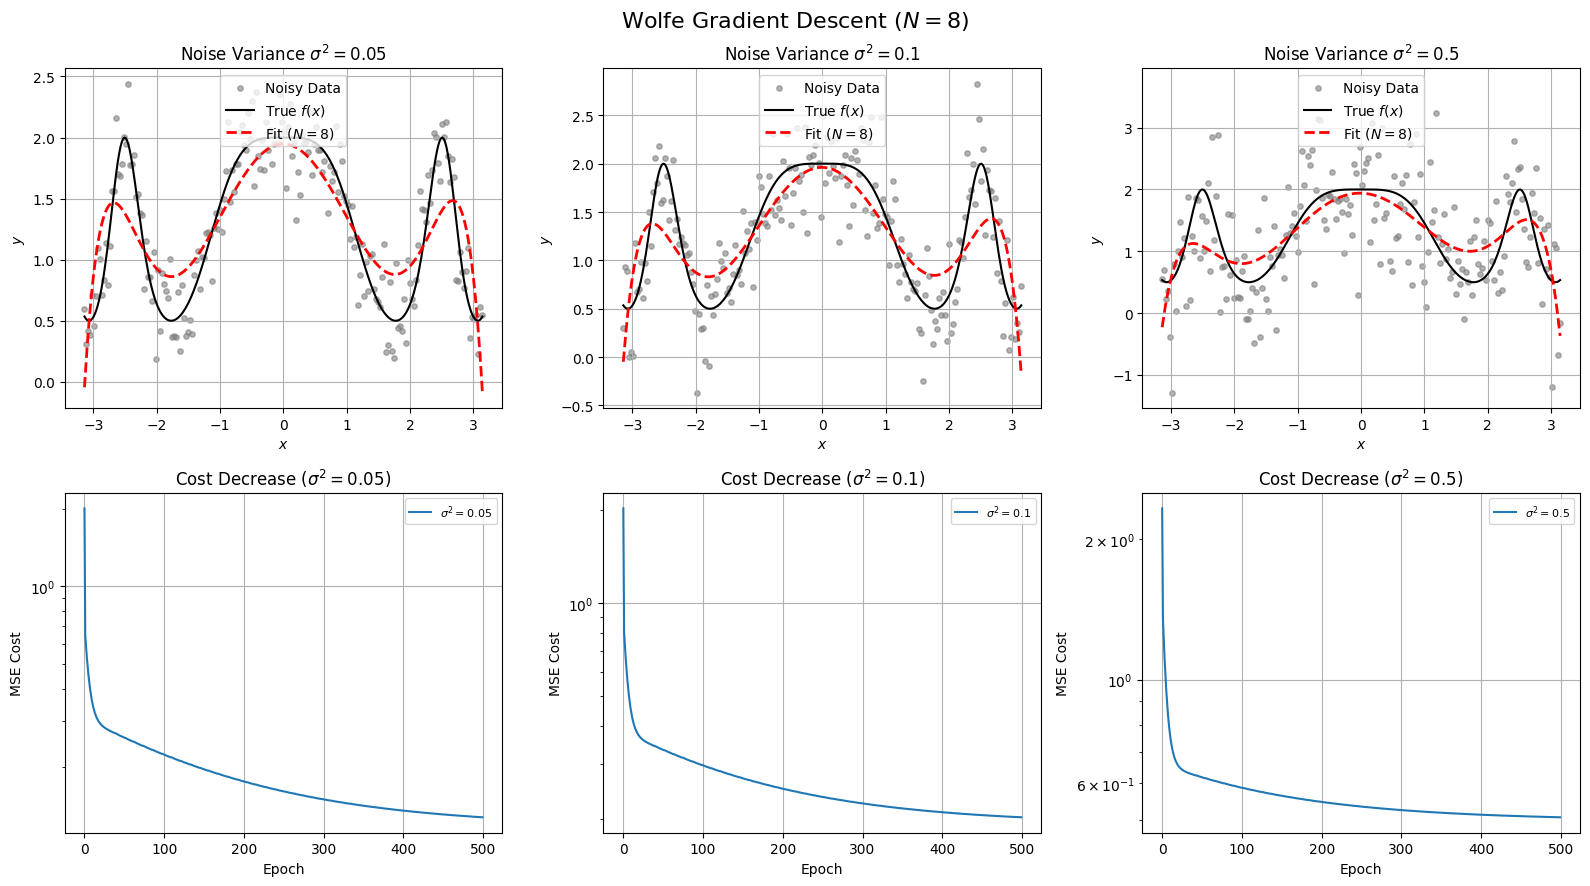

In [49]:
N = 8  # Polynomial degree
sigma_sq_values = [0.05, 0.1, 0.5]

plt.figure(figsize=(16, 9))
x_dense = np.linspace(-np.pi, np.pi, 300)

for idx, sigma_sq in enumerate(sigma_sq_values, 1):
    theta, cost_history, x_data, y_noisy = optimize_with_noise(N=N, sigma_sq=sigma_sq, seed=42 + idx)

    # Evaluate model predictions
    X_dense = np.vander(x_dense, N + 1, increasing=True)
    y_pred = X_dense @ theta

    # Top Row: Solution Fits against Noisy Data
    plt.subplot(2, 3, idx)
    plt.scatter(x_data, y_noisy, color='gray', alpha=0.6, s=15, label='Noisy Data')
    plt.plot(x_dense, f_true(x_dense), 'k-', linewidth=1.5, label='True $f(x)$')
    plt.plot(x_dense, y_pred, 'r--', linewidth=2, label=f'Fit ($N={N}$)')
    plt.title(f'Noise Variance $\\sigma^2 = {sigma_sq}$')
    plt.xlabel('$x$')
    plt.ylabel('$y$')
    plt.legend(loc='upper center')
    plt.grid(True)

    # Bottom Row: Cost History over Epochs
    plt.subplot(2, 3, idx + 3)
    plt.plot(cost_history, color='tab:blue', label=f'$\\sigma^2 = {sigma_sq}$')
    plt.title(f'Cost Decrease ($\\sigma^2 = {sigma_sq}$)')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Cost')
    plt.yscale('log')
    plt.legend(fontsize=8)
    plt.grid(True)

plt.suptitle(f'Wolfe Gradient Descent ($N={N}$)', fontsize=16)
plt.tight_layout()
plt.show()

Even with noise added to the optimization process, the Cost Decrease curve of the deterministic algorithm remained smooth.

### Mini-batch

In [50]:
def compute_cost_and_grad(theta, X, y):
    """
    Computes MSE cost and gradient over a batch.
    """
    batch_size = len(y)
    predictions = X @ theta
    error = predictions - y
    cost = np.mean(error ** 2)
    grad = (2.0 / batch_size) * (X.T @ error)
    return cost, grad

def minibatch_gd_with_noise(N, sigma_sq, m=200, batch_size=32, lr=0.05, epochs=2500, seed=42):
    """
    Optimizes polynomial coefficients using Mini-batch Gradient Descent
    with a constant learning rate, feature standardization, and noise injection.
    """
    np.random.seed(seed)

    # 1. Generate clean domain data
    x = np.linspace(-np.pi + 1e-5, np.pi - 1e-5, m)
    y_clean = f_true(x)

    # 2. Inject Gaussian noise N(0, sigma^2) into target values
    noise = np.random.normal(loc=0.0, scale=np.sqrt(sigma_sq), size=m)
    y_noisy = y_clean + noise

    # 3. Construct Vandermonde matrix for raw polynomial features [1, x, x^2, ..., x^N]
    X = np.vander(x, N + 1, increasing=True)

    # 4. Feature Standardization for numerical stability across high-degree powers
    X_mean = np.mean(X[:, 1:], axis=0)
    X_std = np.std(X[:, 1:], axis=0)
    X_scaled = X.copy()
    X_scaled[:, 1:] = (X[:, 1:] - X_mean) / X_std

    # 5. Initialize parameters in scaled space
    theta_scaled = np.zeros(N + 1)
    cost_history = []

    num_batches = int(np.ceil(m / batch_size))

    for epoch in range(epochs):
        # Shuffle dataset at the start of each epoch
        indices = np.random.permutation(m)
        X_shuffled = X_scaled[indices]
        y_shuffled = y_noisy[indices]

        epoch_cost = 0.0

        for b in range(num_batches):
            start_idx = b * batch_size
            end_idx = min(start_idx + batch_size, m)

            X_batch = X_shuffled[start_idx:end_idx]
            y_batch = y_shuffled[start_idx:end_idx]

            # Compute batch cost and gradient
            batch_cost, grad = compute_cost_and_grad(theta_scaled, X_batch, y_batch)
            epoch_cost += batch_cost * (end_idx - start_idx)

            # Constant learning rate gradient descent step
            theta_scaled -= lr * grad

        # Log average epoch cost across all dataset points
        epoch_cost /= m
        cost_history.append(epoch_cost)

    # 6. Unscale parameters back to original raw monomial basis: y = X @ theta
    theta = np.zeros(N + 1)
    theta[0] = theta_scaled[0] - np.sum(theta_scaled[1:] * X_mean / X_std)
    theta[1:] = theta_scaled[1:] / X_std

    return theta, cost_history, x, y_noisy

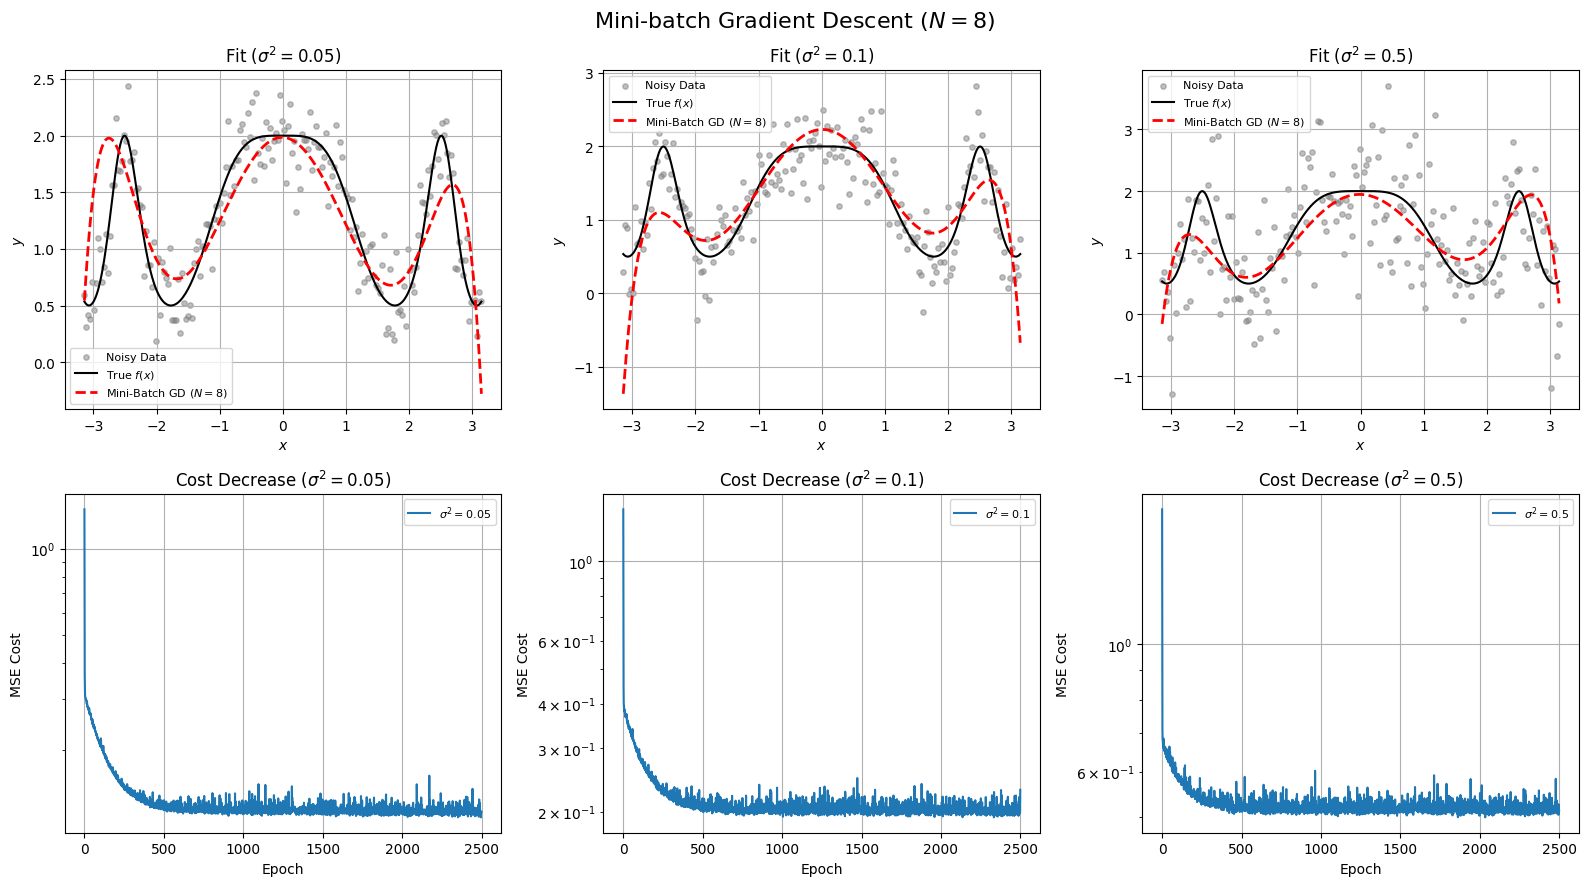

In [51]:
N = 8                       # Polynomial degree
sigma_sq_values = [0.05, 0.1, 0.5]  # Noise variance levels
batch_size = 32
learning_rate = 0.05        # Constant learning rate for standardized features
epochs = 2500

plt.figure(figsize=(16, 9))
x_dense = np.linspace(-np.pi, np.pi, 300)

for idx, sigma_sq in enumerate(sigma_sq_values, 1):
    theta, cost_history, x_data, y_noisy = minibatch_gd_with_noise(
        N=N, sigma_sq=sigma_sq, batch_size=batch_size,
        lr=learning_rate, epochs=epochs, seed=42 + idx
    )

    X_dense = np.vander(x_dense, N + 1, increasing=True)
    y_pred = X_dense @ theta

    # Top Row: Solution Fits against Noisy Data
    plt.subplot(2, 3, idx)
    plt.scatter(x_data, y_noisy, color='gray', alpha=0.5, s=15, label='Noisy Data')
    plt.plot(x_dense, f_true(x_dense), 'k-', linewidth=1.5, label='True $f(x)$')
    plt.plot(x_dense, y_pred, 'r--', linewidth=2, label=f'Mini-Batch GD ($N={N}$)')
    plt.title(f'Fit ($\\sigma^2 = {sigma_sq}$)')
    plt.xlabel('$x$')
    plt.ylabel('$y$')
    plt.legend(fontsize=8)
    plt.grid(True)

    # Bottom Row: Cost History over Epochs
    plt.subplot(2, 3, idx + 3)
    plt.plot(cost_history, color='tab:blue', label=f'$\\sigma^2 = {sigma_sq}$')
    plt.title(f'Cost Decrease ($\\sigma^2 = {sigma_sq}$)')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Cost')
    plt.yscale('log')
    plt.legend(fontsize=8)
    plt.grid(True)

plt.suptitle(f'Mini-batch Gradient Descent ($N={N}$)', fontsize=16)
plt.tight_layout()
plt.show()

Mini-batch presented excessive variation in its Cost decrease curve. It is noticeable that this variation is increased as the noise signal is amplified.

### Adam optimizer

In [52]:
def compute_cost_and_grad(theta, X, y):
    """
    Computes the MSE cost and gradient over a batch/mini-batch.
    """
    batch_size = len(y)
    predictions = X @ theta
    error = predictions - y
    cost = np.mean(error ** 2)
    grad = (2.0 / batch_size) * (X.T @ error)
    return cost, grad

def minibatch_adam_with_noise(N, sigma_sq, m=200, batch_size=32, lr=0.01,
                               beta1=0.9, beta2=0.999, eps=1e-8, epochs=2500, seed=42):
    """
    Optimizes polynomial coefficients using Mini-batch Adam on noisy data.
    """
    np.random.seed(seed)

    # 1. Generate clean domain data
    x = np.linspace(-np.pi + 1e-5, np.pi - 1e-5, m)
    y_clean = f_true(x)

    # 2. Inject Gaussian noise N(0, sigma^2) into target values
    noise = np.random.normal(loc=0.0, scale=np.sqrt(sigma_sq), size=m)
    y_noisy = y_clean + noise

    # 3. Construct Vandermonde matrix for raw polynomial features [1, x, x^2, ..., x^N]
    X = np.vander(x, N + 1, increasing=True)

    # 4. Feature Standardization for numerical stability across high-degree powers
    X_mean = np.mean(X[:, 1:], axis=0)
    X_std = np.std(X[:, 1:], axis=0)
    X_scaled = X.copy()
    X_scaled[:, 1:] = (X[:, 1:] - X_mean) / X_std

    # 5. Initialize parameters and Adam state variables
    theta_scaled = np.zeros(N + 1)
    m_t = np.zeros(N + 1)  # 1st moment vector
    v_t = np.zeros(N + 1)  # 2nd moment vector
    t = 0                  # Timestep counter

    cost_history = []
    num_batches = int(np.ceil(m / batch_size))

    for epoch in range(epochs):
        # Shuffle dataset at start of each epoch
        indices = np.random.permutation(m)
        X_shuffled = X_scaled[indices]
        y_shuffled = y_noisy[indices]

        epoch_cost = 0.0

        for b in range(num_batches):
            start_idx = b * batch_size
            end_idx = min(start_idx + batch_size, m)

            X_batch = X_shuffled[start_idx:end_idx]
            y_batch = y_shuffled[start_idx:end_idx]

            # Compute batch cost and gradient against noisy observations
            batch_cost, grad = compute_cost_and_grad(theta_scaled, X_batch, y_batch)
            epoch_cost += batch_cost * (end_idx - start_idx)

            # Adam Optimizer Update Step
            t += 1
            m_t = beta1 * m_t + (1.0 - beta1) * grad
            v_t = beta2 * v_t + (1.0 - beta2) * (grad ** 2)

            # Compute bias-corrected moment estimates
            m_hat = m_t / (1.0 - beta1 ** t)
            v_hat = v_t / (1.0 - beta2 ** t)

            # Parameter update with constant learning rate alpha (lr)
            theta_scaled -= lr * m_hat / (np.sqrt(v_hat) + eps)

        # Log average epoch cost across all dataset points
        epoch_cost /= m
        cost_history.append(epoch_cost)

    # 6. Unscale parameters back to original raw monomial basis: y = X @ theta
    theta = np.zeros(N + 1)
    theta[0] = theta_scaled[0] - np.sum(theta_scaled[1:] * X_mean / X_std)
    theta[1:] = theta_scaled[1:] / X_std

    return theta, cost_history, x, y_noisy

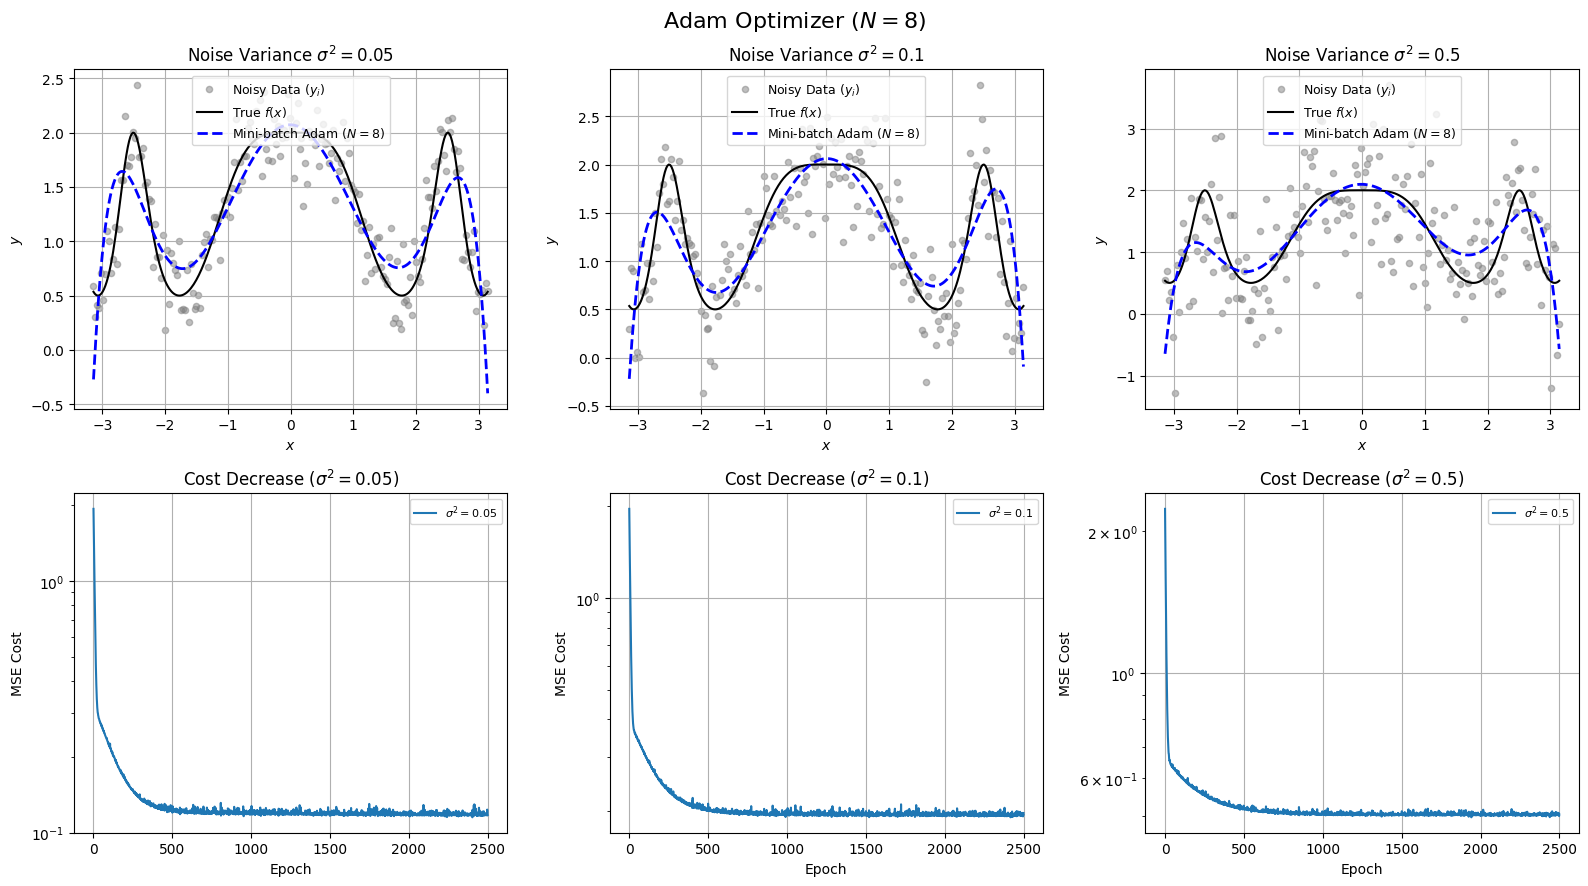

In [53]:
N = 8                       # Polynomial degree
sigma_sq_values = [0.05, 0.1, 0.5]  # Noise variance levels
batch_size = 32
learning_rate = 0.01
epochs = 2500

plt.figure(figsize=(16, 9))
x_dense = np.linspace(-np.pi, np.pi, 300)

for idx, sigma_sq in enumerate(sigma_sq_values, 1):
    # Run optimization with mini-batch Adam + noise
    theta, cost_history, x_data, y_noisy = minibatch_adam_with_noise(
        N=N, sigma_sq=sigma_sq, batch_size=batch_size,
        lr=learning_rate, epochs=epochs, seed=42 + idx
    )

    # Evaluate model predictions on dense grid
    X_dense = np.vander(x_dense, N + 1, increasing=True)
    y_pred = X_dense @ theta

    # Plot fits against noisy observations
    plt.subplot(2, 3, idx)
    plt.scatter(x_data, y_noisy, color='gray', alpha=0.5, s=20, label='Noisy Data ($y_i$)')
    plt.plot(x_dense, f_true(x_dense), 'k-', linewidth=1.5, label='True $f(x)$')
    plt.plot(x_dense, y_pred, 'b--', linewidth=2, label=f'Mini-batch Adam ($N={N}$)')
    plt.title(f'Noise Variance $\\sigma^2 = {sigma_sq}$')
    plt.xlabel('$x$')
    plt.ylabel('$y$')
    plt.legend(loc='upper center', fontsize=9)
    plt.grid(True)

    # Bottom Row: Cost History over Epochs
    plt.subplot(2, 3, idx + 3)
    plt.plot(cost_history, color='tab:blue', label=f'$\\sigma^2 = {sigma_sq}$')
    plt.title(f'Cost Decrease ($\\sigma^2 = {sigma_sq}$)')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Cost')
    plt.yscale('log')
    plt.legend(fontsize=8)
    plt.grid(True)

plt.suptitle(f'Adam Optimizer ($N={N}$)', fontsize=16)
plt.tight_layout()
plt.show()

Finally, the Cost decrease graph for Adam show very little variation. This might be becuase Adam tracks an exponential moving average of past gradients (first moment) and past squared gradients (second moment), which acts as a low-pass filter to smooth out erratic, high-frequency training noise

## Problem 7

Explain using your own words the following:


*a) The differences and similarities between stochastic gradient descent, steepest descent, and minibatch gradient descent.*

While all three optimizaiton methods aim to minimize the cost function by moving in the direction of the negative gradient, they differ in how much data they inspect before taking an update step.

| Feature / Characteristic | Steepest Descent (Full-Batch GD) | Stochastic Gradient Descent (SGD) | Mini-Batch Gradient Descent |
| :--- | :--- | :--- | :--- |
| **Batch Size ($B$)** | Entire dataset ($B = m$) | Single sample ($B = 1$) | Small subset ($1 < B < m$, e.g., 32, 64) |
| **Gradient Accuracy** | **Exact** (true gradient of the cost function over all data) | **Noisy / Unbiased** (high variance estimate from one point) | **Balanced** (low enough variance, highly parallelizable) |
| **Computational Cost per Step** | **Very High** (must process all $m$ samples per update) | **Very Low** (processes only 1 sample per update) | **Moderate** (processes $B$ samples efficiently via matrix vectorization) |
| **Convergence Path** | Smooth, deterministic trajectory directly toward the minimum | Highly erratic, chaotic zig-zagging path | Stable yet slightly fluctuating trajectory |
| **Escaping Local Minima** | **Poor** (can get stuck easily in shallow local minima or saddle points) | **Excellent** (stochastic noise helps bounce out of sharp local traps) | **Good** (controlled noise level helps navigate complex loss landscapes) |
| **Hardware Utilization** | High vectorization potential, but memory-heavy for large datasets | Poor hardware utilization (difficult to vectorize single samples) | **Optimal** (leverages modern GPU/CPU tensor parallelization) |



*b) Some examples of the usage for the latter three cited algorithms (i.e., explain how to identify when an algorithm should be used among the others).*  

**Wolfe Conditions Line Search**  
Since is uses the entire dataset to compute the gradient at each step, it is ideal for small to medium datasets and for low-dimensional problems. Its also useful to compare other stochastic algorithms to it, since it gives an exact trajectory path without stochastic noise.

**Mini-Batch Gradient Descent (Constant Learning Rate)**  
Great for medium to large datasets (thousands or millions of samples). The stochastic noise from batch sampling helps escape poor local minima. It is best used when the features are standardized. However, its learning rate needs to be tuned.

**Adam (Adaptive Moment Estimation)**  
It's the default choice for most applications, because it combines the best features of Momentum (accelerating down ravines) and RMSProp (adapting step sizes per parameter based on historical gradients.


*c) Some examples of the usage of a deterministic approach (Newton, steepest descent, BFGS, Gauss-Newton, etc) and a stochastic approach (stochastic gradient descent, minibatch gradient descent, Adam, etc), i.e., explain how to identify when a particular approach should be used on top of another.*  

It depends greatly on the characteristics of the problem to be tackled. Deterministic (full-batch) methods give exact gradients and paths, but are computationally expensive and poor at escaping local minima. On the other hand, stochastic algorithms, while noisy because of mini-batch sampling, are very cheap in computation time and memory, and excellent at escaping local minima (precisely because of their randomness).

When a smooth, reproducible trajectory without noise is needed and learning rate tuning is undesirable, a deterministic approach is best. Some examples of this would be verifying analytical convergence rates, benchmarking optimization bounds, or solving low-dimensional physical/mathematical systems.

When the error surface is riddled with sharp local minima, ravines, and saddle points, and the dataset is very large, a stochastic approach is best. It is used for almost all modern machine learning, deep learning, and large-scale regression tasks.
